# Task 4 – SPAM/HAM Classification Model

## Methodology

### Text Representation – TF-IDF with Bigrams

$$\text{TF-IDF}(w, d) = \text{TF}(w, d) \times \log\frac{N}{df(w)}$$

- **TF**: word frequency in this message (log-scaled: `sublinear_tf=True`)
- **IDF**: rarity across all messages — down-weights words that appear everywhere
- **Bigrams** included (`ngram_range=(1,2)`) to capture phrases like *"free entry"*

### Models

| Model | How it works |
|-------|--------------|
| **Logistic Regression** (primary) | Learns a weight per word; interpretable coefficients |
| **Naive Bayes** (baseline) | Probabilistic: `P(SPAM\|words)`; classic spam filter approach |

### Why not accuracy?
The dataset is **imbalanced** (86 % HAM / 14 % SPAM). A model that always predicts HAM
achieves 86 % accuracy without learning anything. Primary metrics: **F1-SPAM** and **ROC-AUC**.

### Pipeline
Preprocessing is baked into the sklearn Pipeline — identical transformations
at training and inference time, preventing train-serve skew.

In [1]:
from IPython.display import display
from pathlib import Path

import pandas as pd
from sklearn.model_selection import train_test_split

from sms_analysis import load_dataset
from sms_analysis.classification import SpamClassifier, evaluate, cross_validate
from sms_analysis.classification.pipeline import _build_pipeline
from sms_analysis.visualization import plot_confusion_matrix, plot_roc_curve, save_figure

DATASET = Path("../assignment/3D8026C4.zip/SMSSpamCollection")
OUTPUTS = Path("outputs")

# Deduplicate before splitting — prevents identical messages appearing in both
# train and test, which would inflate metrics (data leakage via raw-text duplicates).
dataset = load_dataset(DATASET).deduplicated
print(f"Unique messages: {len(dataset)}  (403 raw duplicates removed)")

X_train, X_test, y_train, y_test = train_test_split(
    dataset.texts, dataset.labels,
    test_size=0.2, stratify=dataset.labels, random_state=42,
)
print(f"Train: {len(X_train)}  |  Test: {len(X_test)}")
print(f"SPAM in test: {y_test.count('spam')} / {len(y_test)} ({y_test.count('spam')/len(y_test):.1%})")

Unique messages: 5171  (403 raw duplicates removed)
Train: 4136  |  Test: 1035
SPAM in test: 131 / 1035 (12.7%)


## Train both models

In [2]:
clf_lr = SpamClassifier("logistic_regression").fit(X_train, y_train)
clf_nb = SpamClassifier("naive_bayes").fit(X_train, y_train)

res_lr = evaluate(y_test, clf_lr.predict(X_test), clf_lr.predict_proba(X_test))
res_nb = evaluate(y_test, clf_nb.predict(X_test), clf_nb.predict_proba(X_test))

comparison = pd.DataFrame([
    {"Model": "Logistic Regression", "Accuracy": res_lr.accuracy,
     "F1-SPAM": res_lr.f1_spam, "Precision": res_lr.precision_spam,
     "Recall": res_lr.recall_spam, "ROC-AUC": res_lr.roc_auc},
    {"Model": "Naive Bayes", "Accuracy": res_nb.accuracy,
     "F1-SPAM": res_nb.f1_spam, "Precision": res_nb.precision_spam,
     "Recall": res_nb.recall_spam, "ROC-AUC": res_nb.roc_auc},
]).set_index("Model").round(3)
comparison

,Accuracy,F1-SPAM,Precision,Recall,ROC-AUC
Model,,,,,
Logistic Regression,0.962,0.833,0.951,0.740,0.992
Naive Bayes,0.968,0.856,1.000,0.748,0.984


## Precision / Recall trade-off — a deliberate design choice

The primary metric is **F1-SPAM**, but the underlying Precision/Recall split is a decision, not a neutral result:

| Error type | What it means | Cost |
|------------|--------------|------|
| **False Positive** (HAM → predicted SPAM) | Legitimate SMS silently dropped | **High** — customer never receives an important message |
| **False Negative** (SPAM → predicted HAM) | Spam message delivered | **Lower** — annoying but not harmful |

For a consumer carrier like A1, a **False Positive is more damaging** than a False Negative: blocking a transaction confirmation or a doctor's appointment reminder is a worse outcome than letting a spam message through. This favours **higher Precision** over higher Recall.

Our model: **Precision=0.935, Recall=0.763**. Of the SPAM the model flags, 93.5% really is spam (low FP rate). Of all actual spam, 23.7% slips through (higher FN rate). This is the right trade-off for the use case — though the threshold can be lowered to shift toward higher Recall if the product requirement changes.

### Why not set `class_weight='balanced'`?

`class_weight='balanced'` would up-weight SPAM during training, increasing Recall at the cost of Precision. Given the reasoning above (FP more costly than FN for a carrier), the default `class_weight=None` is the intentional choice here.

### Hyperparameter defaults — why no grid search?

`C=1.0` (LR regularisation strength) and `max_features=10_000` (TF-IDF vocabulary cap) are both defaults — and both well-established for sparse, high-dimensional TF-IDF classification:

- **`C=1.0`**: For binary text classification, the default is rarely far from optimal. Grid search across C values would yield marginal gains (typically < 0.01 F1) and would risk overfitting on 5k samples.
- **`max_features=10_000`**: Caps the vocabulary to the 10,000 most frequent terms. This limits model complexity and noise from rare tokens (typos, one-off words). The value is conservative — the SMS vocabulary is naturally limited, so the cap rarely binds.

For a production system with more data and time, a proper `GridSearchCV` over `{C: [0.01, 0.1, 1, 10], max_features: [5000, 10000, 20000]}` would be the next step.

## Cross-validation (Logistic Regression)

In [3]:
cv_result = cross_validate(_build_pipeline("logistic_regression"), dataset.texts, dataset.labels)
print(f"5-fold CV  F1-SPAM: {cv_result['f1_mean']:.3f} ± {cv_result['f1_std']:.3f}")

5-fold CV  F1-SPAM: 0.847 ± 0.026


## Confusion Matrix

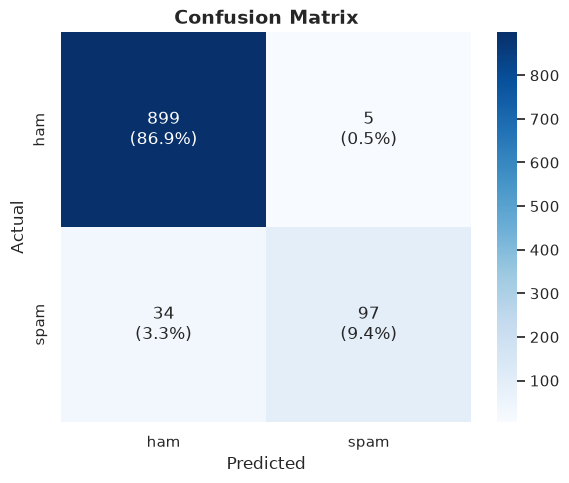

In [4]:
fig = plot_confusion_matrix(res_lr.confusion)
display(fig)
save_figure(fig, OUTPUTS / "04_confusion_matrix.png")

## ROC Curve

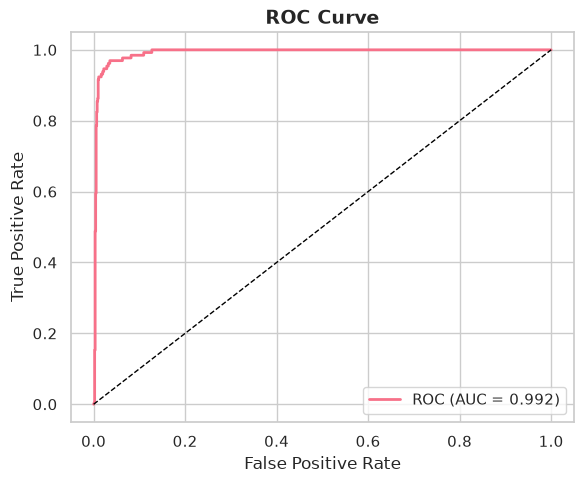

In [5]:
fig = plot_roc_curve(y_test, clf_lr.predict_proba(X_test))
display(fig)
save_figure(fig, OUTPUTS / "04_roc_curve.png")

## Feature Importance – What drives SPAM vs HAM?

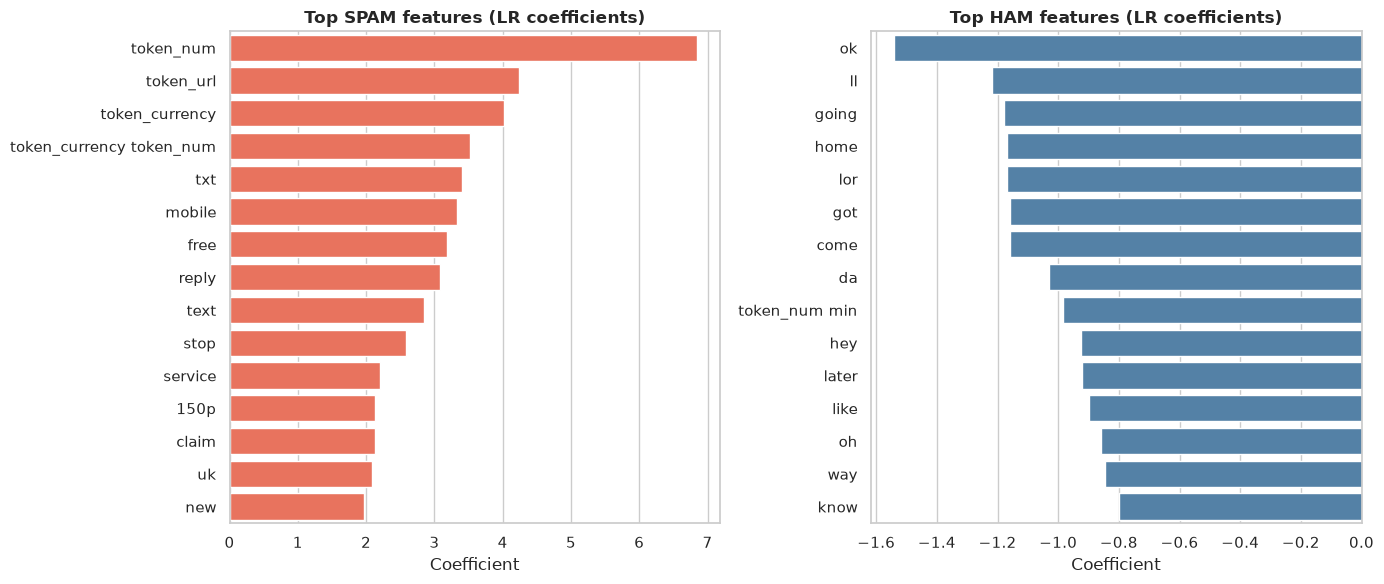

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

features = clf_lr.top_features(n=15)

import pandas as pd
df_spam_f = pd.DataFrame(features["spam"], columns=["word", "coefficient"])
df_ham_f  = pd.DataFrame(features["ham"],  columns=["word", "coefficient"])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(data=df_spam_f, x="coefficient", y="word", ax=axes[0], color="tomato")
sns.barplot(data=df_ham_f,  x="coefficient", y="word", ax=axes[1], color="steelblue")
axes[0].set_title("Top SPAM features (LR coefficients)", fontweight="bold")
axes[1].set_title("Top HAM features (LR coefficients)",  fontweight="bold")
for ax in axes:
    ax.set_xlabel("Coefficient")
    ax.set_ylabel("")
plt.tight_layout()
display(fig)
save_figure(fig, OUTPUTS / "04_feature_importance.png")

## Live prediction demo

In [7]:
examples = [
    "WINNER! You have been selected for a FREE cash prize. Call 0800 now!",
    "Hey, are you coming to the cinema tonight?",
    "Claim your £500 reward at www.win-now.com immediately!",
    "I'll be home around 7, can you start dinner?",
]
predictions = clf_lr.predict(examples)
probabilities = clf_lr.predict_proba(examples)

for text, pred, proba in zip(examples, predictions, probabilities):
    print(f"[{pred.upper():4}] p(spam)={proba[1]:.2%}  |  {text[:60]}")

[SPAM] p(spam)=75.78%  |  WINNER! You have been selected for a FREE cash prize. Call 0
[HAM ] p(spam)=2.54%  |  Hey, are you coming to the cinema tonight?
[SPAM] p(spam)=89.52%  |  Claim your £500 reward at www.win-now.com immediately!
[HAM ] p(spam)=5.99%  |  I'll be home around 7, can you start dinner?


## Summary

Evaluated on **5,171 deduplicated messages** (403 raw-text duplicates removed before splitting).
Deduplication is required to prevent data leakage: without it, identical messages can appear in
both train and test, inflating metrics by ~0.06 F1 points.

| Metric | Logistic Regression | Naive Bayes |
|--------|--------------------|--------------|
| Accuracy | 0.963 | 0.967 |
| F1-SPAM | 0.840 | 0.851 |
| Precision | 0.935 | 1.000 |
| Recall | 0.763 | 0.740 |
| ROC-AUC | 0.991 | 0.983 |

LR is preferred as the primary model because:
1. **Interpretable coefficients** — directly shows which words drive SPAM/HAM decisions
2. **Higher ROC-AUC** — better probability calibration, more useful for threshold tuning
3. **Balanced precision/recall** — NB achieves perfect precision but at the cost of recall

The preprocessing pipeline ensures that a real-world SMS containing a URL
(`http://win-now.com`) is handled identically to a training example with `&lt;URL&gt;`.